# ANALYSIS OF A TRAJECTORY

# General Procedure

The input of this notebook is a 3D trajectory (which __must be in SI__) of a colloid diffusing near a wall. 

This notebook is made to compute a few observables related to the dynamics of the colloid. Those observables are: the distribution of positions relative to the wall, the MSDs, and the local vertical diffusion profile.

# Importations

In [1]:
import numpy as np
from scipy.io import loadmat, savemat
from scipy.optimize import curve_fit , minimize 
from scipy.integrate import trapezoid
from tqdm import tqdm

In [3]:
from StochasticForceInference.StochasticForceInference import *
from StochasticForceInference.fun_SFI import Compute_diffusion
# Get the SFI package on personal Github.

In [4]:
# import ComputeObservables as co
# Personnal .py with functions used to compute observables (PDF, forces, etc.). 
# Copy past the .py in site-packages or in the same floder as the notebook.

In [5]:
%matplotlib inline

import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
import matplotlib as mpl
from matplotlib import rc
import matplotlib.colors as mplcolors
from mpltools import annotation

rc('lines', linewidth=1.5, markeredgecolor='k', markeredgewidth=1)
rc('xtick', direction='in', labelsize=9)
rc('ytick', direction='in', labelsize=9)

rc('font', family='serif', size=9)
rc('text', usetex=True)

rc('figure', dpi=200)
rc('savefig', dpi=200)

# Auxiliary functions

In [6]:
def open_xyz_mat(pathname, upward=False):
    # gives a 3-column array: x, y, z (columns) of time (lines)
    data = loadmat(pathname, squeeze_me=True)
    raw_data = np.zeros((len(data['x']), 3))
    raw_data[:,0] = data['x']
    raw_data[:,1] = data['y']
    raw_data[:,2] = data['z']
    if upward:
        raw_data[:,2] = - raw_data[:,2]
    del data
    return raw_data

In [26]:
# =============================================================================
# Operations on arrays
# =============================================================================

def movmin(datas, k):
    result = np.empty_like(datas)
    start_pt = 0
    end_pt = int(np.ceil(k / 2))

    for i in range(len(datas)):
        if i < int(np.ceil(k / 2)):
            start_pt = 0
        if i > len(datas) - int(np.ceil(k / 2)):
            end_pt = len(datas)
        result[i] = np.nanmin(datas[start_pt:end_pt])
        start_pt += 1
        end_pt += 1

    return result

def movmean(datas, k):
    result = np.empty_like(datas)
    start_pt = 0
    end_pt = int(np.ceil(k / 2))

    for i in range(len(datas)):
        if i < int(np.ceil(k / 2)):
            start_pt = 0
        if i > len(datas) - int(np.ceil(k / 2)):
            end_pt = len(datas)
        result[i] = np.mean(datas[start_pt:end_pt])
        start_pt += 1
        end_pt += 1

    return result

In [32]:
def moment(n, x, t, return_std = False, retrieve_mean = False, mean_abs = False):
    """
    Parameters
    ----------
    n: int, moment of order n
    x: array containing the values of interest
    t: an array containing differences of indexes.
    """
    res = np.zeros(len(t))
    std = np.zeros(len(t))
    for i, j in enumerate(t):
        #x_tau = x[j:] - np.mean(x[j:])
        #x_zer = x[0:-j] - np.mean(x[0:-j])
        #res[i] = np.nanmean((x_tau - x_zer)**n)
        Delta_x = x[j:] - x[0:-j]
        if retrieve_mean:
            distribution = (Delta_x - np.mean(Delta_x)) ** n
        else:
            distribution = (Delta_x) ** n
        if mean_abs:
            distribution = np.abs(distribution)
        res[i] = np.nanmean(distribution)
        std[i] = np.nanstd(distribution)
    if return_std:
        return res, std
    else:
        return res

In [7]:
def pdf(data, bins=10, density=True, range=None):
    pdf, bins_edge = np.histogram(
        data, 
        bins=bins, 
        density=density, 
        range=range, 
    )
    bins_center = (bins_edge[0:-1] + bins_edge[1:]) / 2
    return pdf, bins_center

def logarithmic_hist(data, begin, stop, num=50, base=2, density=True):
    if begin == 0:
        beg = stop / num
        bins = np.logspace(
            np.log(beg) / np.log(base), 
            np.log(stop) / np.log(base), 
            num - 1, 
            base=base, 
        )
        widths = bins[1:] - bins[:-1]
        bins = np.cumsum(widths[::-1])
        bins = np.concatenate(([0], bins))
        widths = bins[1:] - bins[:-1]
    else:
        bins = np.logspace(
            np.log(begin) / np.log(base), 
            np.log(stop) / np.log(base), 
            num, 
            base=base, 
        )
        widths = bins[1:] - bins[:-1]
    hist, a = np.histogram(data, bins=bins, density=density)
    # normalize by bin width
    bins_center = (bins[1:] + bins[:-1]) / 2
    return bins_center, widths, hist

# Load the data

In [8]:
# where to find the data

directory = '../MieActiveBrownian/results/20251203_test_9_p2/data_exp_Active_exp_20251203_analysis_20260515_filename_traj_rp_2p3112_np_1p5906_vid_p2.mat'
filename = directory[directory.rfind('/')+1:]

In [9]:
filename

'data_exp_Active_exp_20251203_analysis_20260515_filename_traj_rp_2p3112_np_1p5906_vid_p2.mat'

In [10]:
##########

#####

#

# enter the parameters

# Radius 
r = float(filename[filename.find('_rp_')+4:filename.find('_np_')].replace('p','.')) * 1e-6
# r = 2.66e-6
# Difference of density
drho = 20
# density of the medium
rho_m = 1000
# viscosity
eta_m = 0.001

# frame rate of video
fps = 100

# calibration (um / px)
calib = 0.058

print(r)

# 

#####

##########

2.3112e-06


In [11]:
# open the trajectory 
raw_data = open_xyz_mat(directory, upward=False) # 3-column array: x, y, z (columns) of time (lines)

In [12]:
raw_data

array([[ 2.12291625e-05,  1.84392901e-06,  1.88577137e-07],
       [ 2.12435659e-05,  1.81144899e-06,  1.99972673e-07],
       [ 2.12352656e-05,  1.81203821e-06,  1.86751952e-07],
       ...,
       [-9.88558834e-06,  1.53253198e-05,  6.99030219e-07],
       [-9.88375331e-06,  1.52745058e-05,  7.14797326e-07],
       [-9.85643069e-06,  1.52369483e-05,  6.94574500e-07]],
      shape=(360009, 3))

In [13]:
# # Remove zeros at the end of the trajectory:
# try:
#     ind = list(raw_data[:,0]).index(0)
#     raw_data = raw_data[:ind,:]
# except ValueError:
#     print('No pb. No zero in raw data.')

In [14]:
# if you want to keep only a part of the trajectory 
raw_data = raw_data[:,:]

In [15]:
# Define ''absolute'' time
N_tot_frames = len(raw_data[:, 0])
frames = np.arange(N_tot_frames)
time = np.arange(0, np.shape(raw_data)[0]) / fps

In [16]:
# Reference point (e.g. something stuck on the surface)
directory_ref = ''
# If you don't have a reference, the reference's trajectory is set to zeros later in the code.

In [17]:
# Load the trajectory of the reference
# For now, it is not used. 
# The trajectory of the reference is artificially set to zero.
try:
    raw_data_ref = open_xyz_mat(directory_ref, upward=False)
except FileNotFoundError as err:
    print(err)
    raw_data_ref = np.zeros(np.shape(raw_data))
    print()
    print('The trajectory of the reference has been set to zero')
except:
    print("Unknow error!")

[Errno 2] No such file or directory: '.mat'

The trajectory of the reference has been set to zero


In [18]:
# Initialize the save (in a dictionnary)
where_to_save_the_data = "./"
tosave = {}

In [19]:
# # Set garde fou to modify and/or compute some data only once.
# garde_fou_1 = True
# garde_fou_2 = True
# garde_fou_3 = True
# garde_fou_4 = True

In [20]:
# Save data

tosave['filename'] = filename
tosave["fps"] = fps
tosave["r"] = r
tosave["time"] = np.copy(time)

# __Watch the Raw Trajectory__

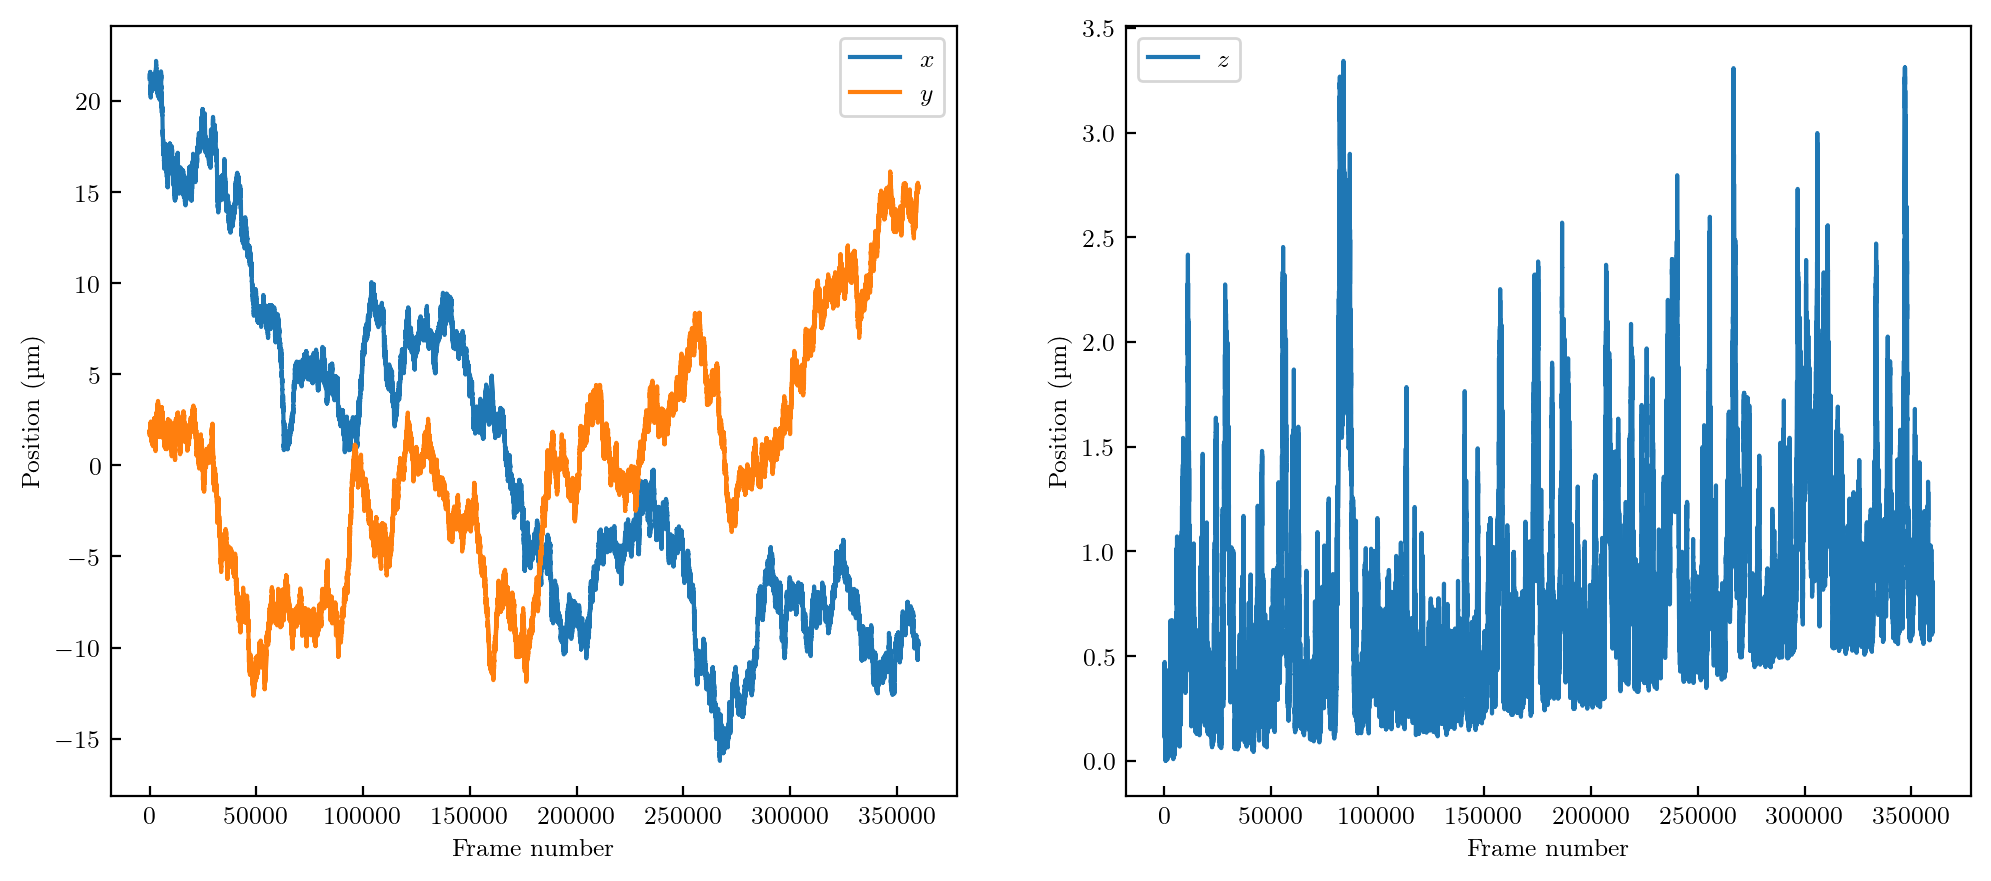

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
axx, axz = axes[0], axes[1]

# fig.canvas.toolbar_visible = True
# fig.canvas.header_visible = True
# fig.canvas.resizable = True

axx.plot(time * fps, raw_data[:, 0] * 1e6, label="$x$")
axx.plot(time * fps, raw_data[:, 1] * 1e6, label="$y$")
axz.plot(time * fps, raw_data[:, 2] * 1e6, label="$z$")

axx.set_xlabel("Frame number")
axx.set_ylabel("Position (µm)")
axz.set_xlabel("Frame number")
axz.set_ylabel("Position (µm)")

axx.legend()
axz.legend()

plt.show() 

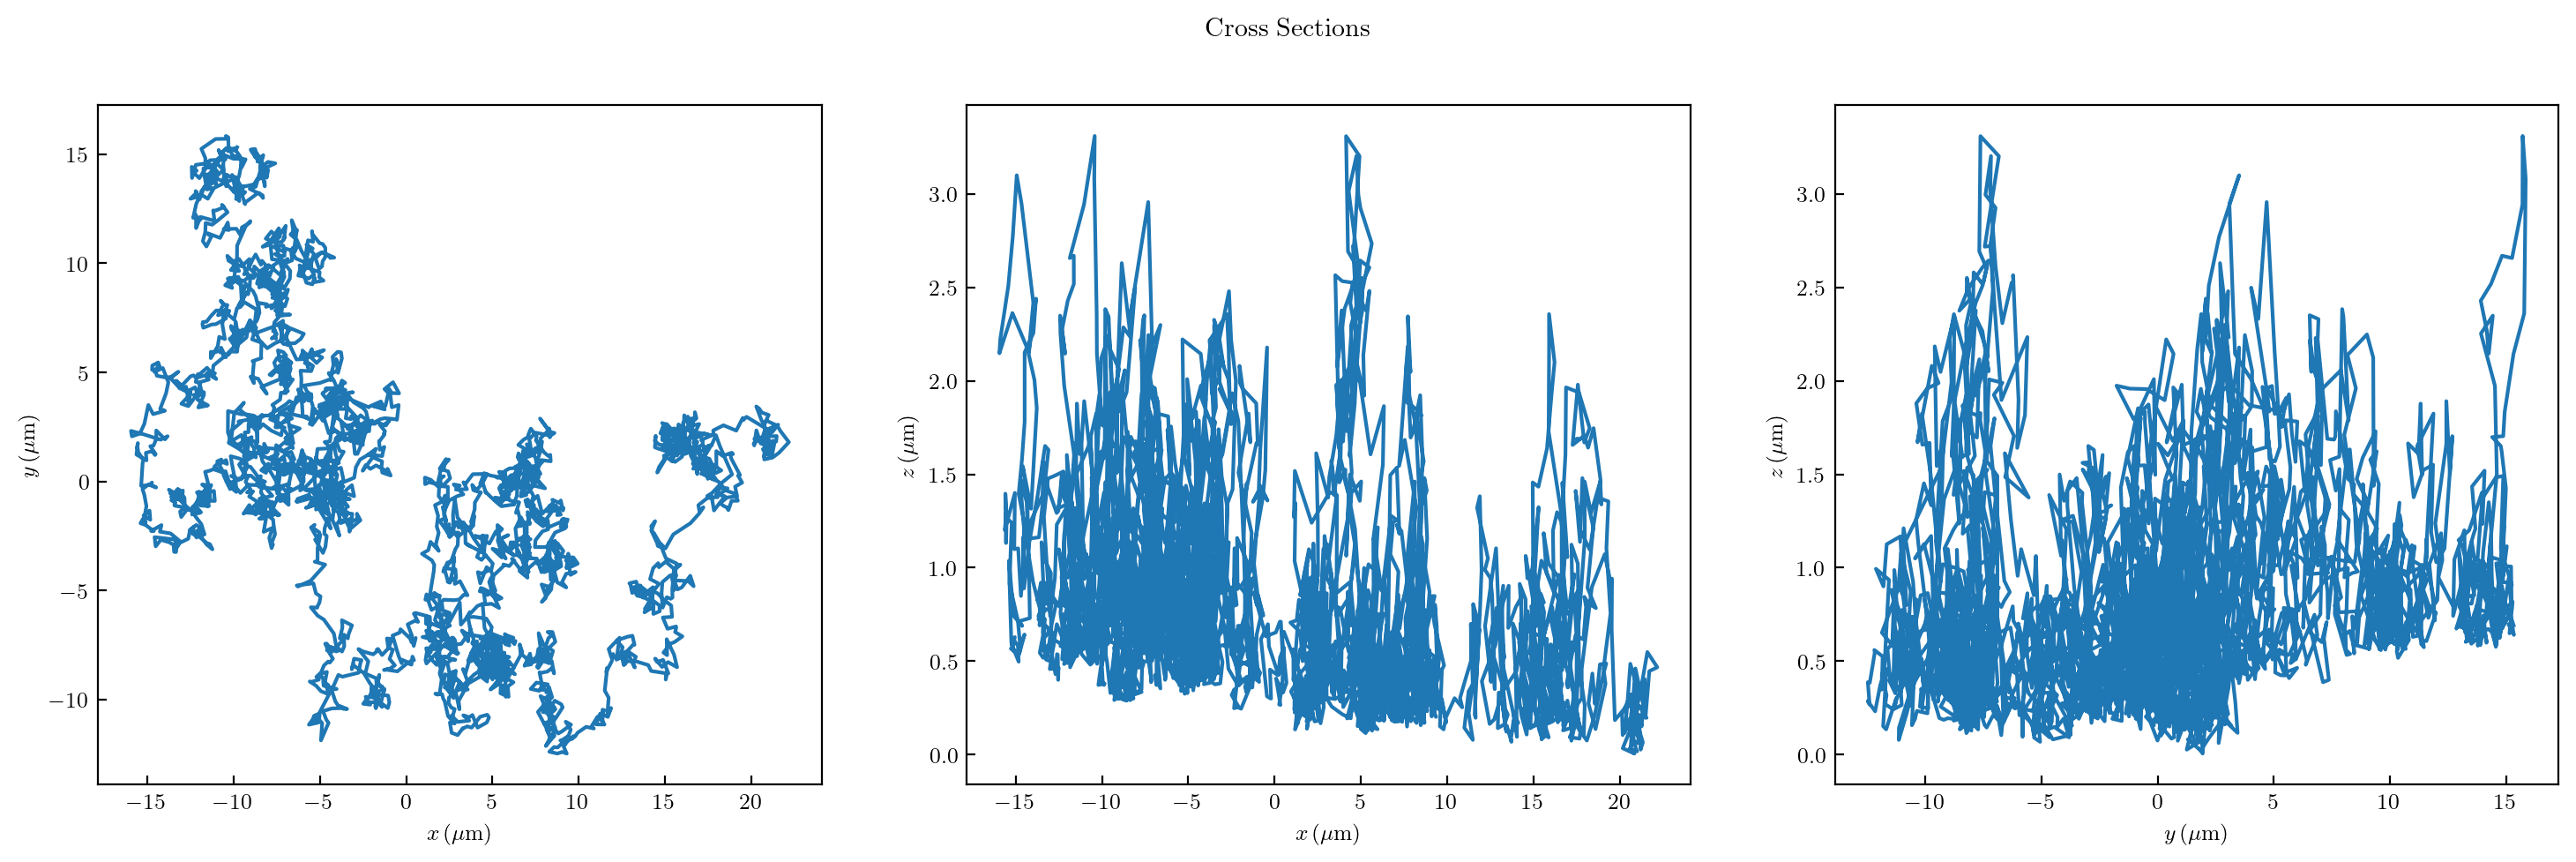

In [22]:
# Profiles of the trajectory

fig, axes = plt.subplots(1, 3, figsize=(18,5))
axxy, axxz, axyz = axes[0], axes[1], axes[2]

axxy.plot(raw_data[::100, 0] * 1e6, raw_data[::100, 1] * 1e6)
axxz.plot(raw_data[::100, 0] * 1e6, raw_data[::100, 2] * 1e6)
axyz.plot(raw_data[::100, 1] * 1e6, raw_data[::100, 2] * 1e6)

axxy.set_xlabel("$x \, \mathrm{(\mu m)}$")
axxy.set_ylabel("$y \, \mathrm{(\mu m)}$")
axxz.set_xlabel("$x \, \mathrm{(\mu m)}$")
axxz.set_ylabel("$z \, \mathrm{(\mu m)}$")
axyz.set_xlabel("$y \, \mathrm{(\mu m)}$")
axyz.set_ylabel("$z \, \mathrm{(\mu m)}$")

fig.suptitle("Cross Sections")

plt.show()

# __Correct Trajectories with a reference__

## Look at the reference

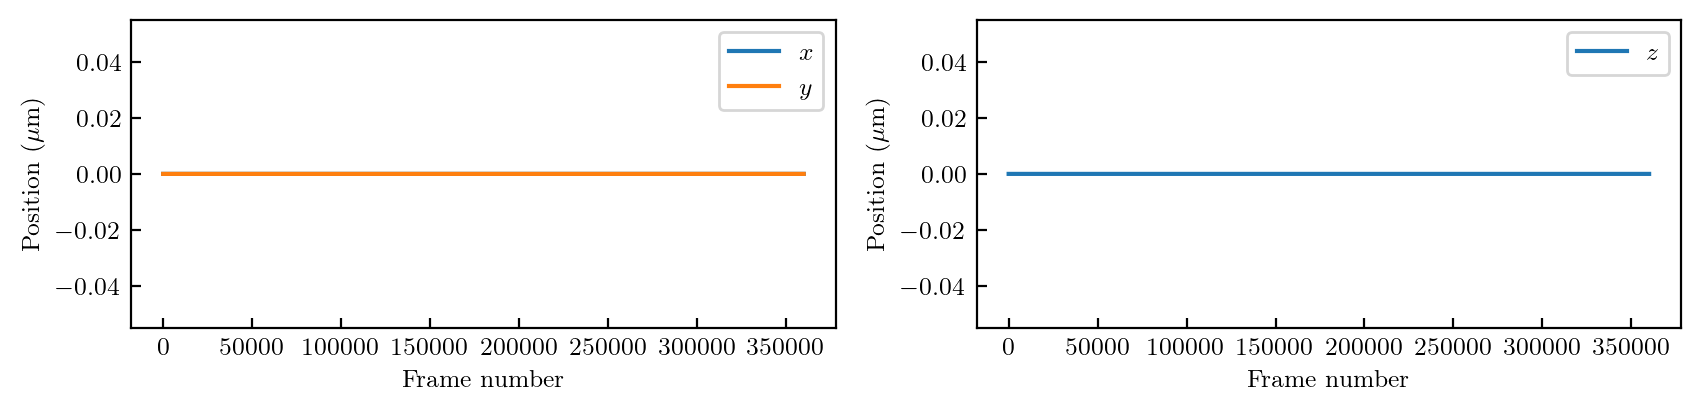

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10,2))
axx, axz = axes[0], axes[1]

axx.plot(time * fps, raw_data_ref[:, 0] * 1e6, label="$x$")
axx.plot(time * fps, raw_data_ref[:, 1] * 1e6, label="$y$")
axz.plot(time * fps, raw_data_ref[:, 2] * 1e6, label="$z$")

axx.set_xlabel("Frame number")
axx.set_ylabel("Position $\mathrm{(\mu m)}$")
axz.set_xlabel("Frame number")
axz.set_ylabel("Position $\mathrm{(\mu m)}$")

axx.legend()
axz.legend()

plt.show()

In [27]:
nb_points_ref = 10000
smooth_xref = movmean(raw_data_ref[:, 0], nb_points_ref)
smooth_yref = movmean(raw_data_ref[:, 1], nb_points_ref)
smooth_zref = movmean(raw_data_ref[:, 2], nb_points_ref)

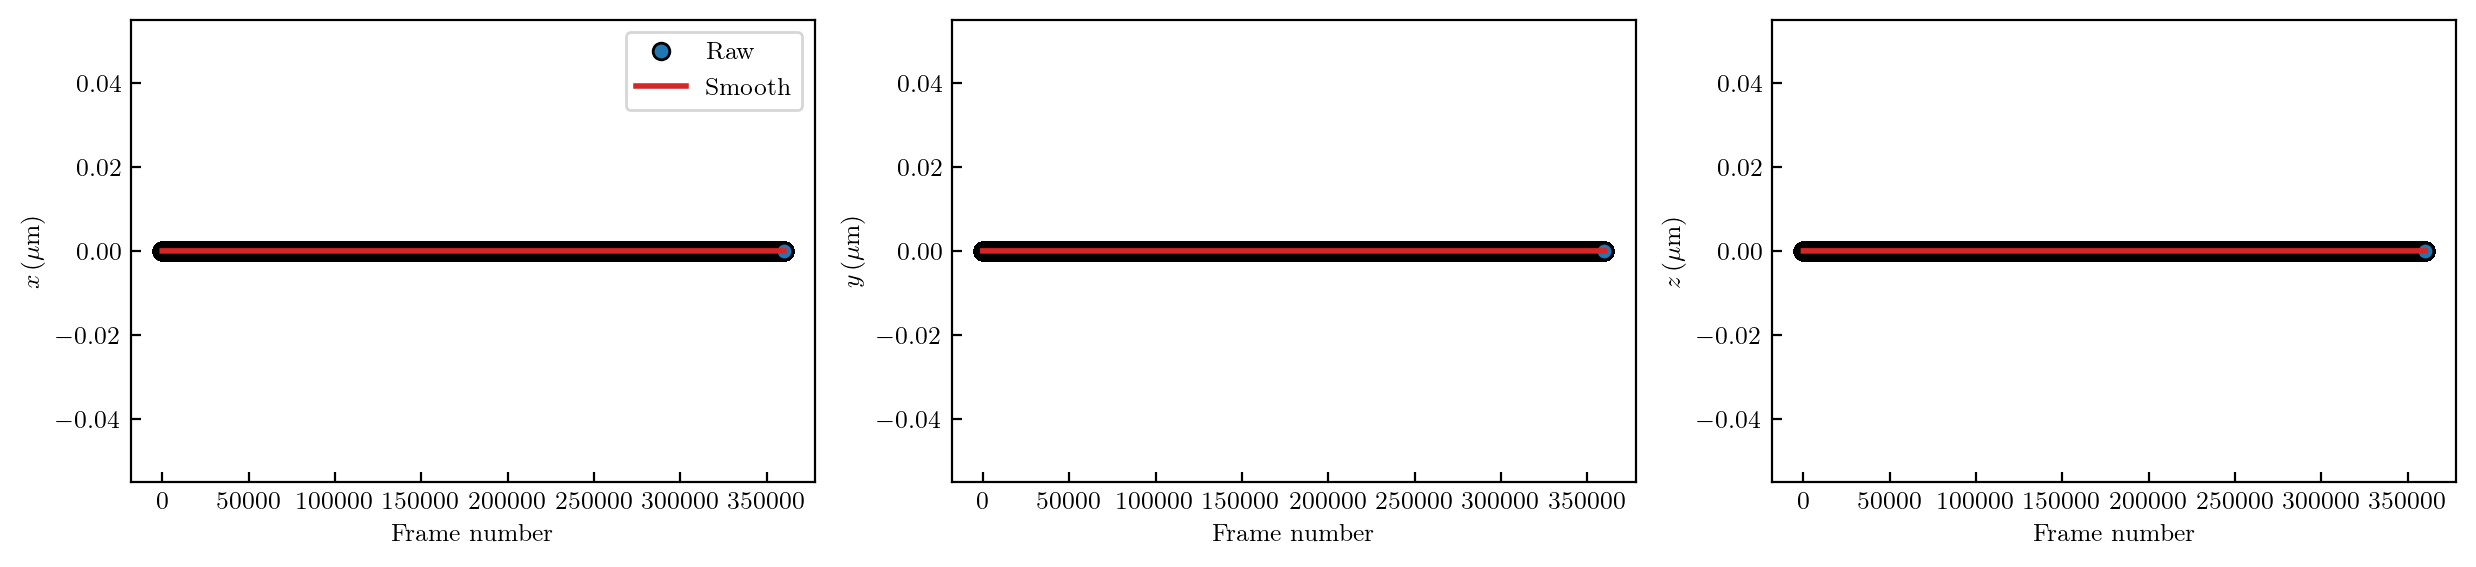

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15,3))
axx, axy, axz = axes[0], axes[1], axes[2]

axx.plot(frames, raw_data_ref[:, 0] * 1e6, ls='', marker='o', markersize=6, c='tab:blue', label="Raw")
axx.plot(frames, smooth_xref * 1e6, ls='-', linewidth=2, c='tab:red', label="Smooth")
axy.plot(frames, raw_data_ref[:, 1] * 1e6, ls='', marker='o', markersize=6, c='tab:blue')
axy.plot(frames, smooth_yref * 1e6, ls='-', linewidth=2, c='tab:red')
axz.plot(frames, raw_data_ref[:, 2] * 1e6, ls='', marker='o', markersize=6, c='tab:blue')
axz.plot(frames, smooth_zref * 1e6, ls='-', linewidth=2, c='tab:red')

axx.legend()

axx.set_xlabel("Frame number")
axx.set_ylabel("$x \, \mathrm{(\mu m)}$")
axy.set_xlabel("Frame number")
axy.set_ylabel("$y \, \mathrm{(\mu m)}$")
axz.set_xlabel("Frame number")
axz.set_ylabel("$z \, \mathrm{(\mu m)}$")

plt.show()

## Add the Corrections to the Sphere's Trajectory

In [29]:
xraw = raw_data[:, 0]
yraw = raw_data[:, 1]
zraw = raw_data[:, 2]

x = xraw - smooth_xref # If no reference, it just retrieves 0.
x = x - np.mean(x)
y = yraw - smooth_yref
y = y - np.mean(y)
z = zraw - smooth_zref
z = z - np.min(z)

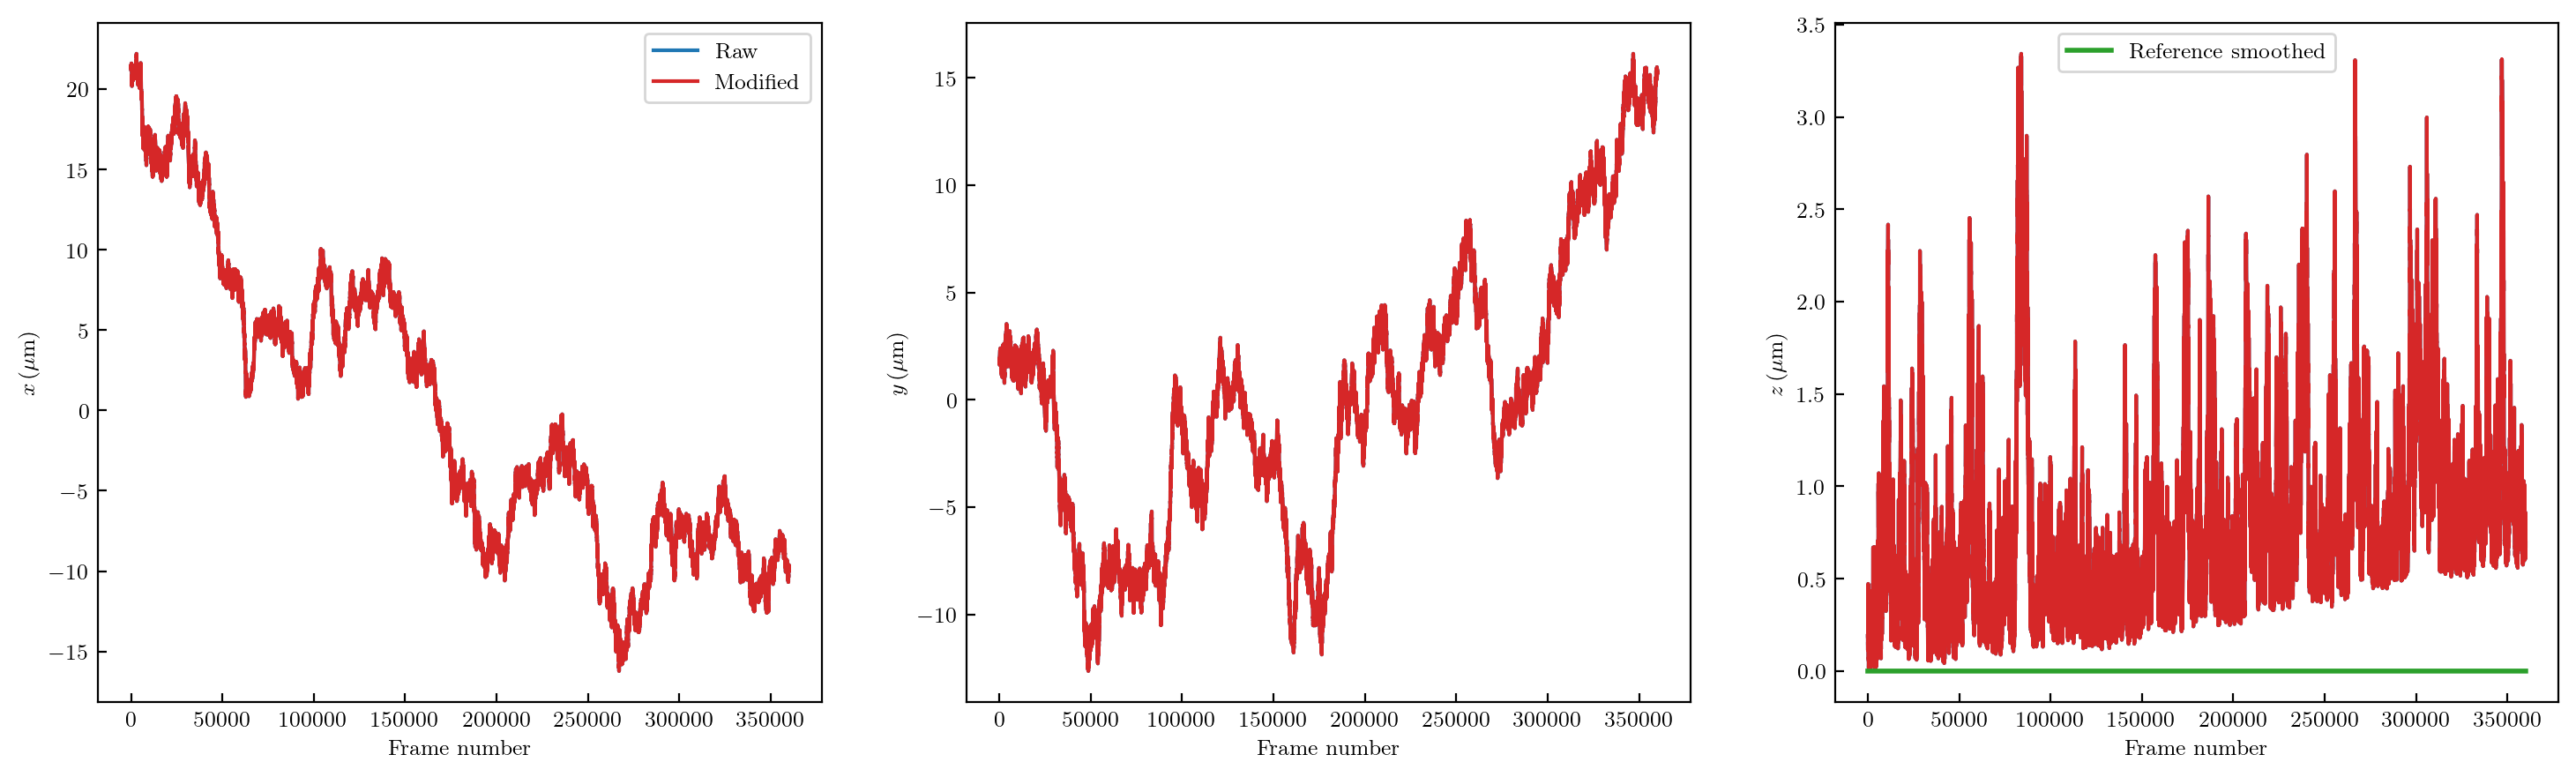

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
axx, axy, axz = axes[0], axes[1], axes[2]

axx.plot(frames, xraw * 1e6 - np.mean(xraw) * 1e6, ls='-', marker='', markersize=6, c='tab:blue', label="Raw")
axx.plot(frames, x * 1e6, ls='-', marker='', markersize=6, c='tab:red', label="Modified")
# axx.plot(frames, smooth_xref * 1e6, ls='-', linewidth=2, c='tab:green', label="Reference smoothed")
axy.plot(frames, yraw * 1e6 - np.mean(yraw) * 1e6, ls='-', marker='', markersize=6, c='tab:blue')
axy.plot(frames, y * 1e6, ls='-', marker='', markersize=6, c='tab:red')
# axy.plot(frames, smooth_yref* 1e6, ls='-', linewidth=2, c='tab:green')
axz.plot(frames, zraw * 1e6 - np.min(zraw) * 1e6, ls='-', marker='', markersize=6, c='tab:blue')
axz.plot(frames, z * 1e6, ls='-', marker='', markersize=6, c='tab:red')
axz.plot(frames, smooth_zref * 1e6 - np.min(raw_data_ref[:,2]) * 1e6, ls='-', linewidth=2, c='tab:green', label="Reference smoothed")

axx.legend()
axz.legend()

axx.set_xlabel(r"Frame number")
axx.set_ylabel(r"$x \, \mathrm{(\mu m)}$")
axy.set_xlabel(r"Frame number")
axy.set_ylabel(r"$y \, \mathrm{(\mu m)}$")
axz.set_xlabel(r"Frame number")
axz.set_ylabel(r"$z \, \mathrm{(\mu m)}$")

plt.show()

In [31]:
# Save data

tosave["xraw"] = np.copy(xraw)
tosave["yraw"] = np.copy(yraw)
tosave["zraw"] = np.copy(zraw)
tosave["x"] = np.copy(x)
tosave["y"] = np.copy(y)
tosave["z"] = np.copy(z)

## Dedrift the $z$-trajectory

/tmp/ipykernel_14693/4050387145.py:24: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_short, _ = curve_fit(


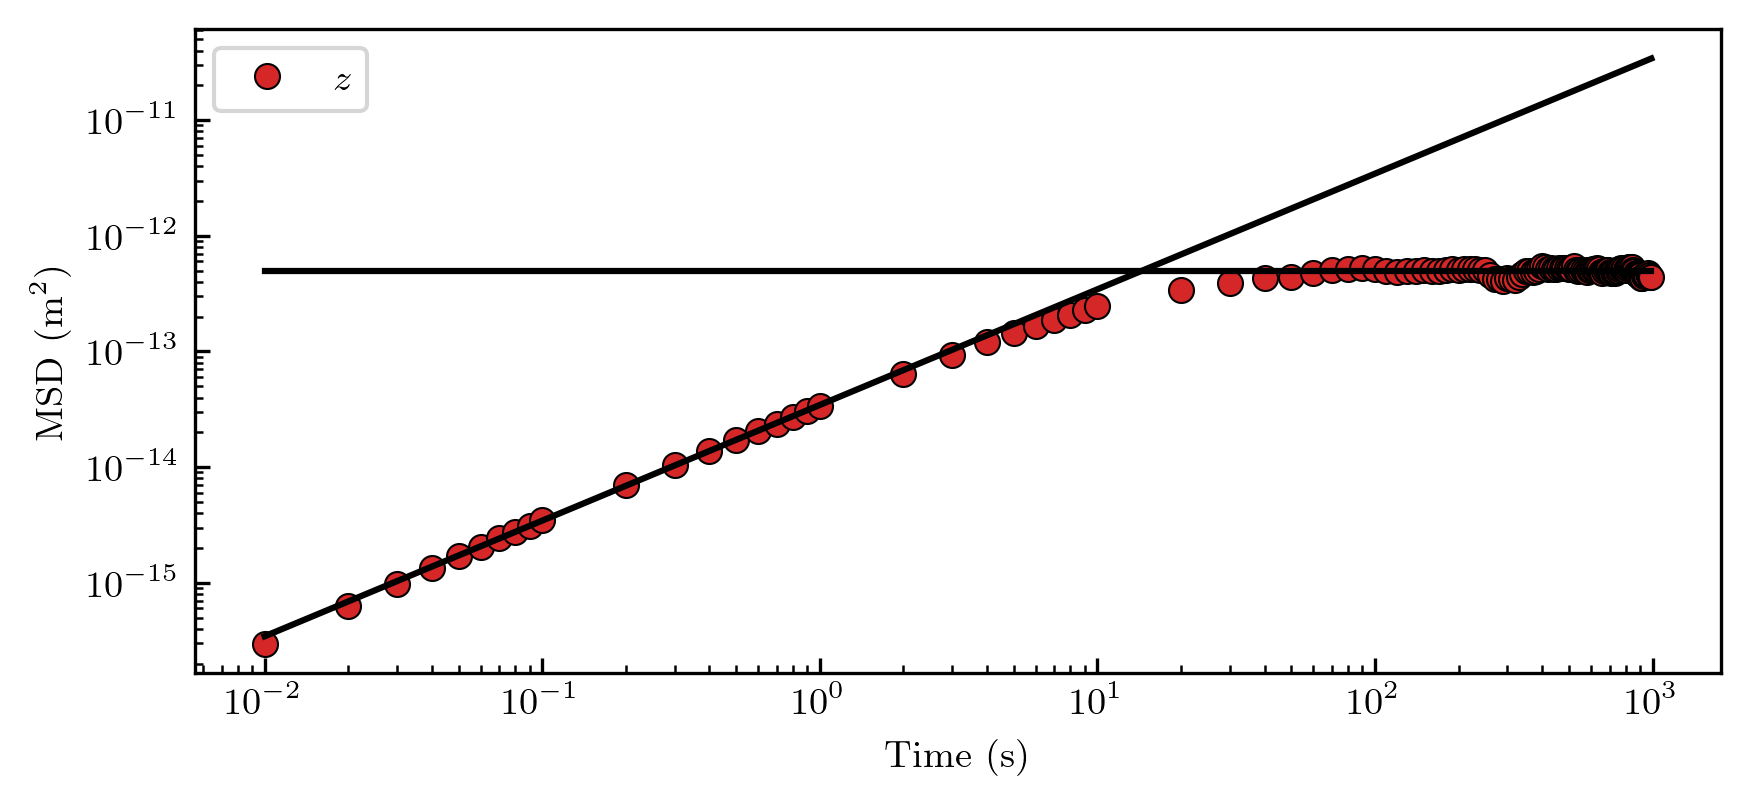

Measured equilibrium time = 14.412092773977955 s
So dedrift time = 25 times the previous time = 360.30231934944885 s = 36030.23193494489 points


In [33]:
step = np.concatenate(
    (
        np.arange(1, 10, 1),
        np.arange(10, 100, 10),
        np.arange(100, 1000, 100),
        np.arange(1000, 100000, 1000),
    )
)
tttt = step / fps

msdz = moment(2, z, step, retrieve_mean = False)

# =======
# Compute 
# =======

# Input times in s
start_short = 0 
stop_short = 0.1
start_long = 50
stop_long = 100

f_short = lambda x, a, b: a*x + (2*b)**2
popt_short, _ = curve_fit(
    f_short, 
    tttt[(tttt >= start_short) & (tttt <= stop_short)], msdz[(tttt >= start_short) & (tttt <= stop_short)], 
    p0=[2 * 0.2 * 4e-21 / (6*np.pi*eta_m*r), 0.], 
)
coef = popt_short[0]
plateau = np.nanmean(msdz[(tttt >= start_long) & (tttt <= stop_long)])

tau_eq = plateau / coef

# ====
# Plot
# ====

fig, ax = plt.subplots(1, 1, figsize = (15 / 2.54, 7 / 2.54), dpi=300)

ax.plot(
    tttt, msdz, 
    'o', markerfacecolor='tab:red', markersize=6, markeredgecolor='k', markeredgewidth=0.5, 
    label="$z$", 
)
ax.plot(tttt, f_short(tttt, *popt_short), '-k')
ax.plot(tttt, np.ones(len(tttt)) * plateau, '-k')

ax.legend()

ax.set(
    xscale='log', 
    yscale='log', 
    xlabel="Time (s)", 
    ylabel="MSD $\mathrm{(m^2)}$", 
)

plt.tight_layout()
plt.show()


# =====
# Print
# =====
print("Measured equilibrium time = {} s".format(tau_eq))
to_be_chosen = tau_eq*25
print("So dedrift time = 25 times the previous time = {0} s = {1} points".format(to_be_chosen, to_be_chosen*fps))

In [34]:
print("Measured equilibrium time = {} s".format(tau_eq))
print("So dedrift time = 25 times the previous time = {0} s = {1} points".format(to_be_chosen, to_be_chosen*fps))

Measured equilibrium time = 14.412092773977955 s
So dedrift time = 25 times the previous time = 360.30231934944885 s = 36030.23193494489 points


In [36]:
# Choose the dedrift nb of points and dedrift the trajectory

#####

###

#

nb_points_to_dedrift = 29000

#

###

#####

z_dedrift = z - movmin(z, nb_points_to_dedrift)
print("Time for dedrift = {} s".format(nb_points_to_dedrift / fps))

Time for dedrift = 290.0 s


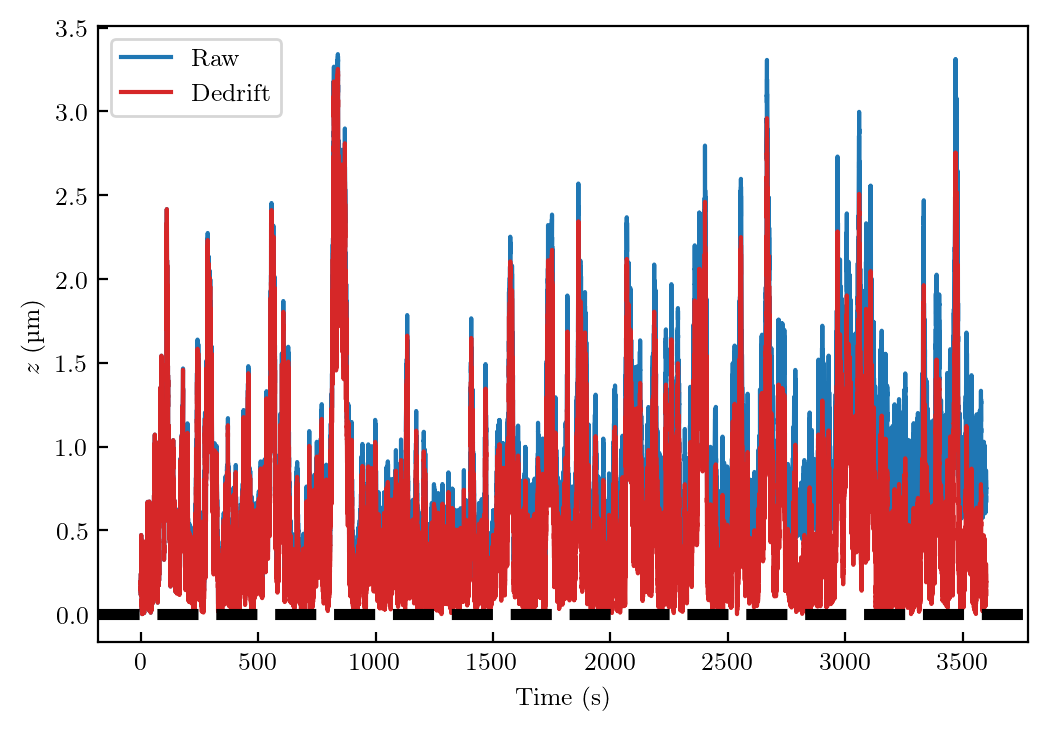

In [37]:
fig, ax = plt.subplots(1, 1, figsize=(6,4))

ax.plot(time, (z - np.min(z)) * 1e6, '-', c='tab:blue', label="Raw")
ax.plot(time, z_dedrift * 1e6, '-', c='tab:red', label="Dedrift")
ax.axhline(y=0, ls='--', color='k', linewidth=4)

ax.set_xlabel("Time (s)")
ax.set_ylabel("$z$ (µm)")

ax.legend()

plt.show()

In [38]:
# Save data

tosave["nb_points_to_dedrift"] = nb_points_to_dedrift
tosave["z_dedrift"] = np.copy(z_dedrift)

# __Analysis of the Trajectory__ 

First, obversables are computed and basic properties are estimated (mean diffusion coefficient, noise levels, etc.). Some of the observables are also fitted independently to check that every observable are correct. 

Second, the multifitting procedure is performed.

# MSD

In [40]:
delta_frame_nb = np.concatenate(
    (
        np.arange(1, 10, 1),
        np.arange(10, 100, 10),
        np.arange(100, 1000, 100),
        np.arange(1000, 70000, 1000),
    )
)

delta_time_MSD = delta_frame_nb / fps

MSD_x, std_MSD_x = moment(2, x, delta_frame_nb, return_std = True, retrieve_mean = True) # Function in wrapper
MSD_y, std_MSD_y = moment(2, y, delta_frame_nb, return_std = True, retrieve_mean = True)
MSD_z, std_MSD_z = moment(2, z_dedrift, delta_frame_nb, return_std = True, retrieve_mean = True)

MSD_para = (MSD_x + MSD_y) / 2
std_MSD_para = (std_MSD_x + std_MSD_y) / 2
MSD_perp = np.copy(MSD_z)
std_MSD_perp = np.copy(std_MSD_z)

In [41]:
D0 = 4e-21 / (6 * np.pi * eta_m * r)
print("D0 = {0:.3e} m^2".format(D0))

D0 = 9.182e-14 m^2


In [42]:
# Fit the MSD 
# Short and long times

start_MSD_x = 0
stop_MSD_x = 10
start_MSD_z = 0
stop_MSD_z = 10
start_long_times = 150 # s
stop_long_times = 200

# Long times

# plateau_MSD_para = (np.nanmean(MSD_x[delta_time_MSD > start_long_times]) + np.nanmean(MSD_y[delta_time_MSD > start_long_times])) / 2
plateau_MSD_perp = np.nanmean(MSD_z[(delta_time_MSD > start_long_times) & (delta_time_MSD < stop_long_times)])

# Short times

def MSD_th(t, reduced_D, noiselevel, tau_e=0):
    return 2 * reduced_D * (1 - tau_e/3/t) * D0 * t + (2 * noiselevel) ** 2

popt_MSD_x, _ = curve_fit(
    MSD_th, 
    delta_time_MSD[start_MSD_x:stop_MSD_x], 
    MSD_x[start_MSD_x:stop_MSD_x], 
    p0 = [0.50, 0.], 
)
popt_MSD_y, _ = curve_fit(
    MSD_th, 
    delta_time_MSD[start_MSD_x:stop_MSD_x], 
    MSD_y[start_MSD_x:stop_MSD_x], 
    p0 = [0.50, 0.], 
)
popt_MSD_z, _ = curve_fit(
    MSD_th, 
    delta_time_MSD[start_MSD_z:stop_MSD_z], 
    MSD_z[start_MSD_z:stop_MSD_z], 
    p0 = [0.25, 0.], 
)

mean_D_para_from_MSD = (popt_MSD_x[0] + popt_MSD_y[0]) / 2
mean_D_perp_from_MSD = popt_MSD_z[0]
noise_level_para_from_MSD = (popt_MSD_x[1] + popt_MSD_y[1]) / 2
noise_level_perp_from_MSD = popt_MSD_z[1]

/tmp/ipykernel_14693/1510035260.py:21: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_MSD_x, _ = curve_fit(
/tmp/ipykernel_14693/1510035260.py:27: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_MSD_y, _ = curve_fit(
/tmp/ipykernel_14693/1510035260.py:33: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_MSD_z, _ = curve_fit(


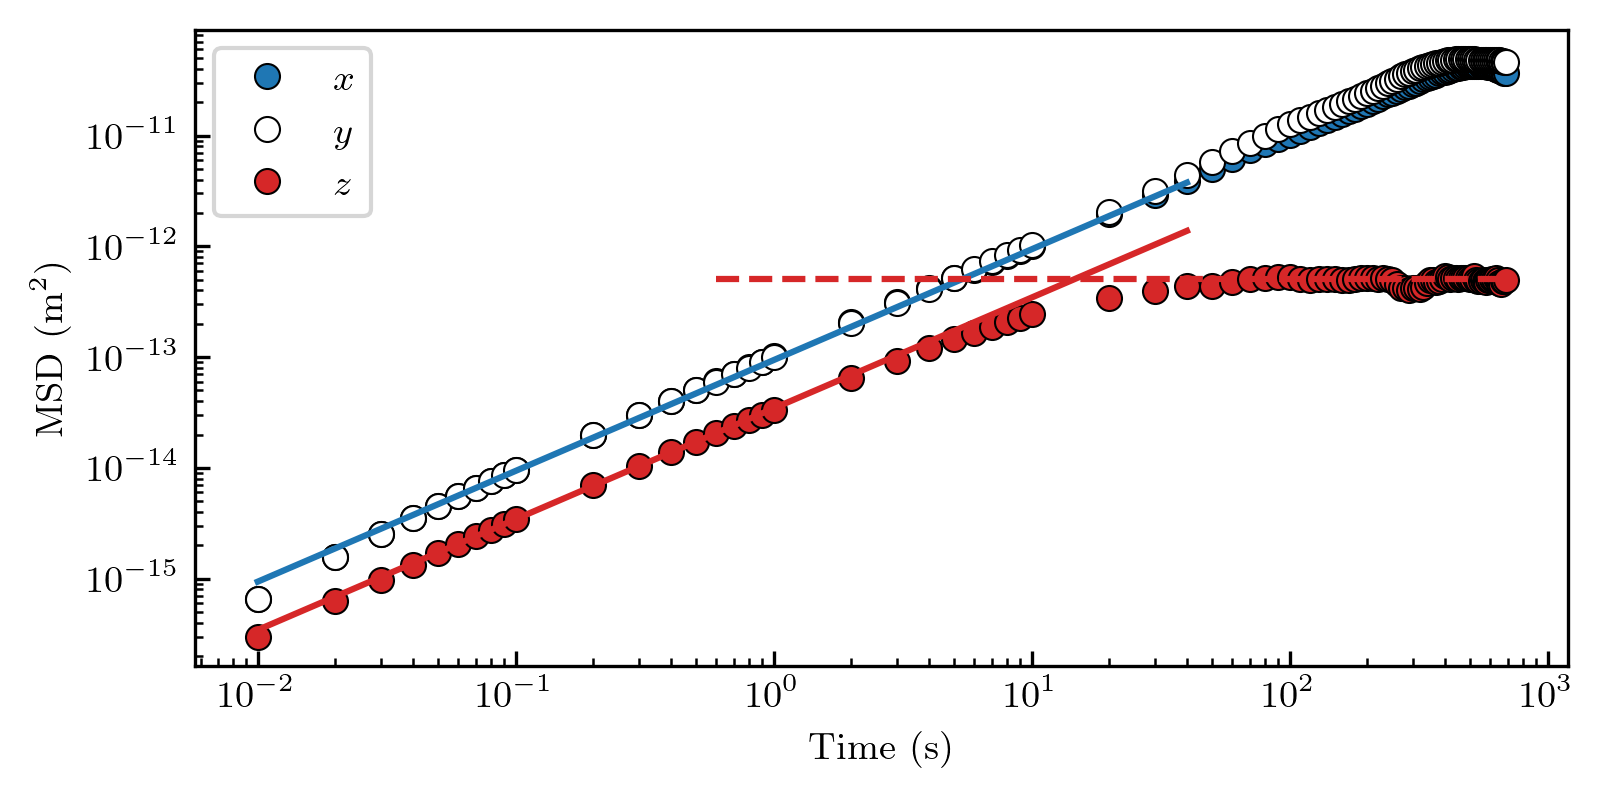

The measured mean diffusion coefficients are:
   0.512D0 in the parallel direction
   0.188D0 in the normal direction
FYI, D0 = 9.182e-14 m^2/s
The measured noise levels are:
   -0.000 nm in the parallel direction
   0.000 nm in the normal direction


In [43]:
fig, ax = plt.subplots(1, 1, figsize = (15 / 2.54, 7 / 2.54), dpi=300)

ax.plot(delta_time_MSD, MSD_x, 'o', markerfacecolor='tab:blue', markersize=6, markeredgecolor='k', markeredgewidth=0.5, label="$x$")
ax.plot(delta_time_MSD, MSD_y, 'o', markerfacecolor='w', markersize=6, markeredgecolor='k', markeredgewidth=0.5, label="$y$")
ax.plot(delta_time_MSD, MSD_z, 'o', markerfacecolor='tab:red', markersize=6, markeredgecolor='k', markeredgewidth=0.5, label="$z$")

ax.plot(delta_time_MSD[delta_time_MSD < 50], MSD_th(delta_time_MSD[delta_time_MSD < 50], *popt_MSD_x), ls='-', c='tab:blue', linewidth=1.5)
ax.plot(delta_time_MSD[delta_time_MSD < 50], MSD_th(delta_time_MSD[delta_time_MSD < 50], *popt_MSD_z), ls='-', c='tab:red', linewidth=1.5)
# ax.plot(delta_time_MSD[delta_time_MSD > 0.5], plateau_MSD_para * np.ones(len(delta_time_MSD[delta_time_MSD > 0.5])), '--', c='tab:blue', linewidth=1.5)
ax.plot(delta_time_MSD[delta_time_MSD > 0.5], plateau_MSD_perp * np.ones(len(delta_time_MSD[delta_time_MSD > 0.5])), '--', c='tab:red', linewidth=1.5)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Time (s)")
ax.set_ylabel(r"MSD $\mathrm{(m^2)}$")

ax.legend()

plt.show()

print("The measured mean diffusion coefficients are:")
print("   {0:.3f}D0 in the parallel direction".format(mean_D_para_from_MSD))
print("   {0:.3f}D0 in the normal direction".format(mean_D_perp_from_MSD))
print("FYI, D0 = {0:.3e} m^2/s".format(D0))
print("The measured noise levels are:")
print("   {0:.3f} nm in the parallel direction".format(noise_level_para_from_MSD * 1e9))
print("   {0:.3f} nm in the normal direction".format(noise_level_perp_from_MSD * 1e9))

In [44]:
# Save data

tosave["D0"] = D0

tosave["delta_frame_nb_MSD"] = np.copy(delta_frame_nb)
tosave["delta_time_MSD"] = np.copy(delta_time_MSD)

tosave["MSD_x"] = np.copy(MSD_x) # The noise levels are already removed from the MSD. 
tosave["MSD_y"] = np.copy(MSD_y)
tosave["MSD_z"] = np.copy(MSD_z)

tosave["MSD_para"] = np.copy(MSD_para)
tosave["MSD_perp"] = np.copy(MSD_perp)

tosave["mean_D_para_from_MSD"] = mean_D_para_from_MSD
tosave["noise_level_para_from_MSD"] = noise_level_para_from_MSD
tosave["mean_D_perp_from_MSD"] = mean_D_perp_from_MSD
tosave["noise_level_perp_from_MSD"] = noise_level_perp_from_MSD

# PDF

In [45]:
# Computation of Peq and Feq

min_distance = 30e-9 
max_distance = 1e-6
n_bins = 40

In [46]:
def PeqFeq(traj_z, min_distance, max_distance, n_bins, kBT=4e-21):
    """
    Compute the equilibrium probability density function and force, as a 
    function to the distance to the wall.
    The trajectory is noised n_noisy times. The final result is the average 
    of every computations.
    
    Parameters
    ----------
    z_dedrift : array
        z-trajectory of the particle.
    min_distance, max_distance : floats
        Spatial range.
    n_bins : int
        Number of bins. 
    

    Returns
    -------
    P_eq, F_eq : two dict
        The dictionnaries contain the data corresponding to the equilibrium PDF
        and force.

    """

    x_P_eq, width_P_eq, y_P_eq = logarithmic_hist(traj_z, min_distance, max_distance, num=n_bins+1, base=2) # Here num is the nb of borders.
    x_F_eq, width_F_eq, y_F_eq = logarithmic_hist(traj_z, min_distance, max_distance, num=n_bins+1, base=2)
    y_F_eq = np.gradient(np.log(y_F_eq), x_F_eq) * kBT
    
    res_P_eq = {
        'x_P_eq': x_P_eq, 
        'width_P_eq': width_P_eq, 
        'y_P_eq': y_P_eq, 
    }
    
    res_F_eq = {
        'x_F_eq': x_F_eq, 
        'width_F_eq': width_F_eq, 
        'y_F_eq': y_F_eq, 
    }
    
    return res_P_eq, res_F_eq

In [47]:
data_P_eq, data_F_eq = PeqFeq(z_dedrift, min_distance, max_distance, n_bins)
# PeqFeq returns two dictionnaries, containing data corresponding to Peq and Feq

x_P_eq, width_P_eq, y_P_eq = data_P_eq.values()
x_F_eq, width_F_eq, y_F_eq = data_F_eq.values()

del data_P_eq, data_F_eq

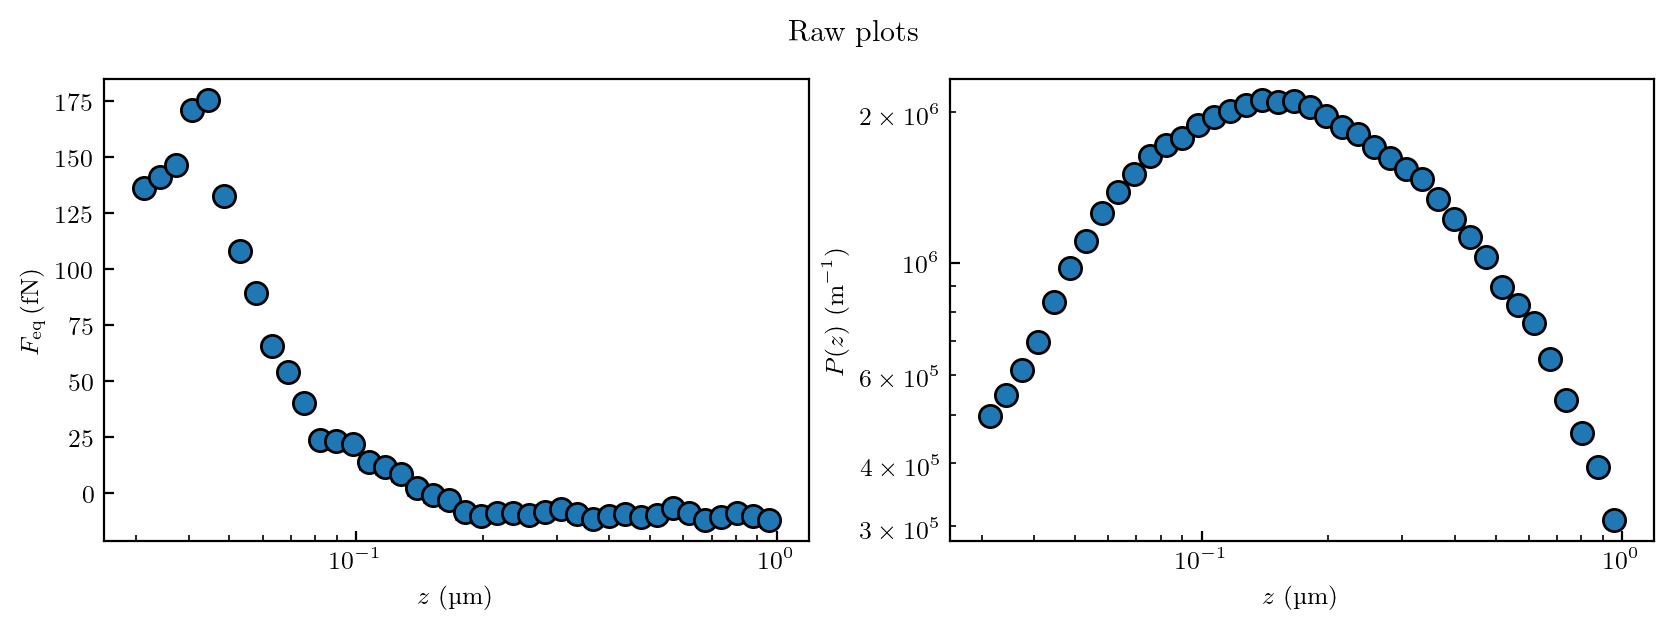

In [48]:
fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(10,3))

ax1.errorbar(x_F_eq * 1e6, y_F_eq * 1e15, yerr=0, xerr=width_F_eq/2*1e6, 
           ls='', marker='o', markersize=8, markerfacecolor='tab:blue', markeredgewidth=1, markeredgecolor='k', 
            ecolor='k', capsize=3,
           )
ax1.set_xlabel("$z$ (µm)")
ax1.set_ylabel("$F_{\mathrm{eq}} \, \mathrm{(fN)}$")
ax1.set_xscale("log")

ax2.errorbar(x_P_eq * 1e6, y_P_eq, yerr=0, xerr=width_P_eq/2*1e6, 
           ls='', marker='o', markersize=8, markerfacecolor='tab:blue', markeredgewidth=1, markeredgecolor='k', 
            ecolor='k', capsize=3,
           )
ax2.set_xlabel("$z$ (µm)")
ax2.set_ylabel("$P(z)$ (m$^{-1}$)")
ax2.set_xscale("log")
ax2.set_yscale("log")

fig.suptitle("Raw plots")

plt.show()

In [49]:
# Find the weight directly on the experimental data
F_grav = np.nanmean([y_F_eq[i] for i in range(len(y_F_eq)) if x_F_eq[i] > 0.3e-6 and x_F_eq[i] < 2e-6])
lB_exp = 4e-21 / abs(F_grav)

lB_theory = 4e-21 / (4 / 3 * np.pi * r**3 * drho * 9.81)

print("Experimental weight = {0:.2f} fN".format(F_grav * 1e15))
print("Experimental Boltzmann length = {0:.1f} nm".format(lB_exp * 1e9))
print("Vs.")
print("Theoretical Boltzmann length = {0:.1f} nm".format(lB_theory * 1e9))

Experimental weight = -9.77 fN
Experimental Boltzmann length = 409.3 nm
Vs.
Theoretical Boltzmann length = 394.2 nm


In [50]:
# Theoretical expressions

# For the moment, lB is fixed in the theoretical equilibrium force.

# Value found in the previous cell. 

# Bad coding... but... ah...

def P_eq_semi_theory(z, B, lD, z0=0):
    """
    z: in m
    """
    z = z - z0
    P_b = np.exp(-B * np.exp(-z / lD) - z / lB_exp)
    P_b[z < 0] = 0
    # Normalization of P_b
    P_b = P_b / np.trapezoid(P_b, z)
    return P_b

def F_eq_semi_theory(x, B, lD, z0=0):
    x = x - z0
    res = 4e-21 * (B / lD * np.exp(- x / lD) - 1 / lB_exp)
    return res 

In [51]:
# Fit the PDF

p0_P_eq = [5, 32e-9, 0]
popt_P_eq, pcov_P_eq = curve_fit(P_eq_semi_theory, x_P_eq, y_P_eq, p0=p0_P_eq)

# if you want to enter values manually, just uncomment the next cell

In [52]:
# popt_P_eq = [5, 25e-9, 0]

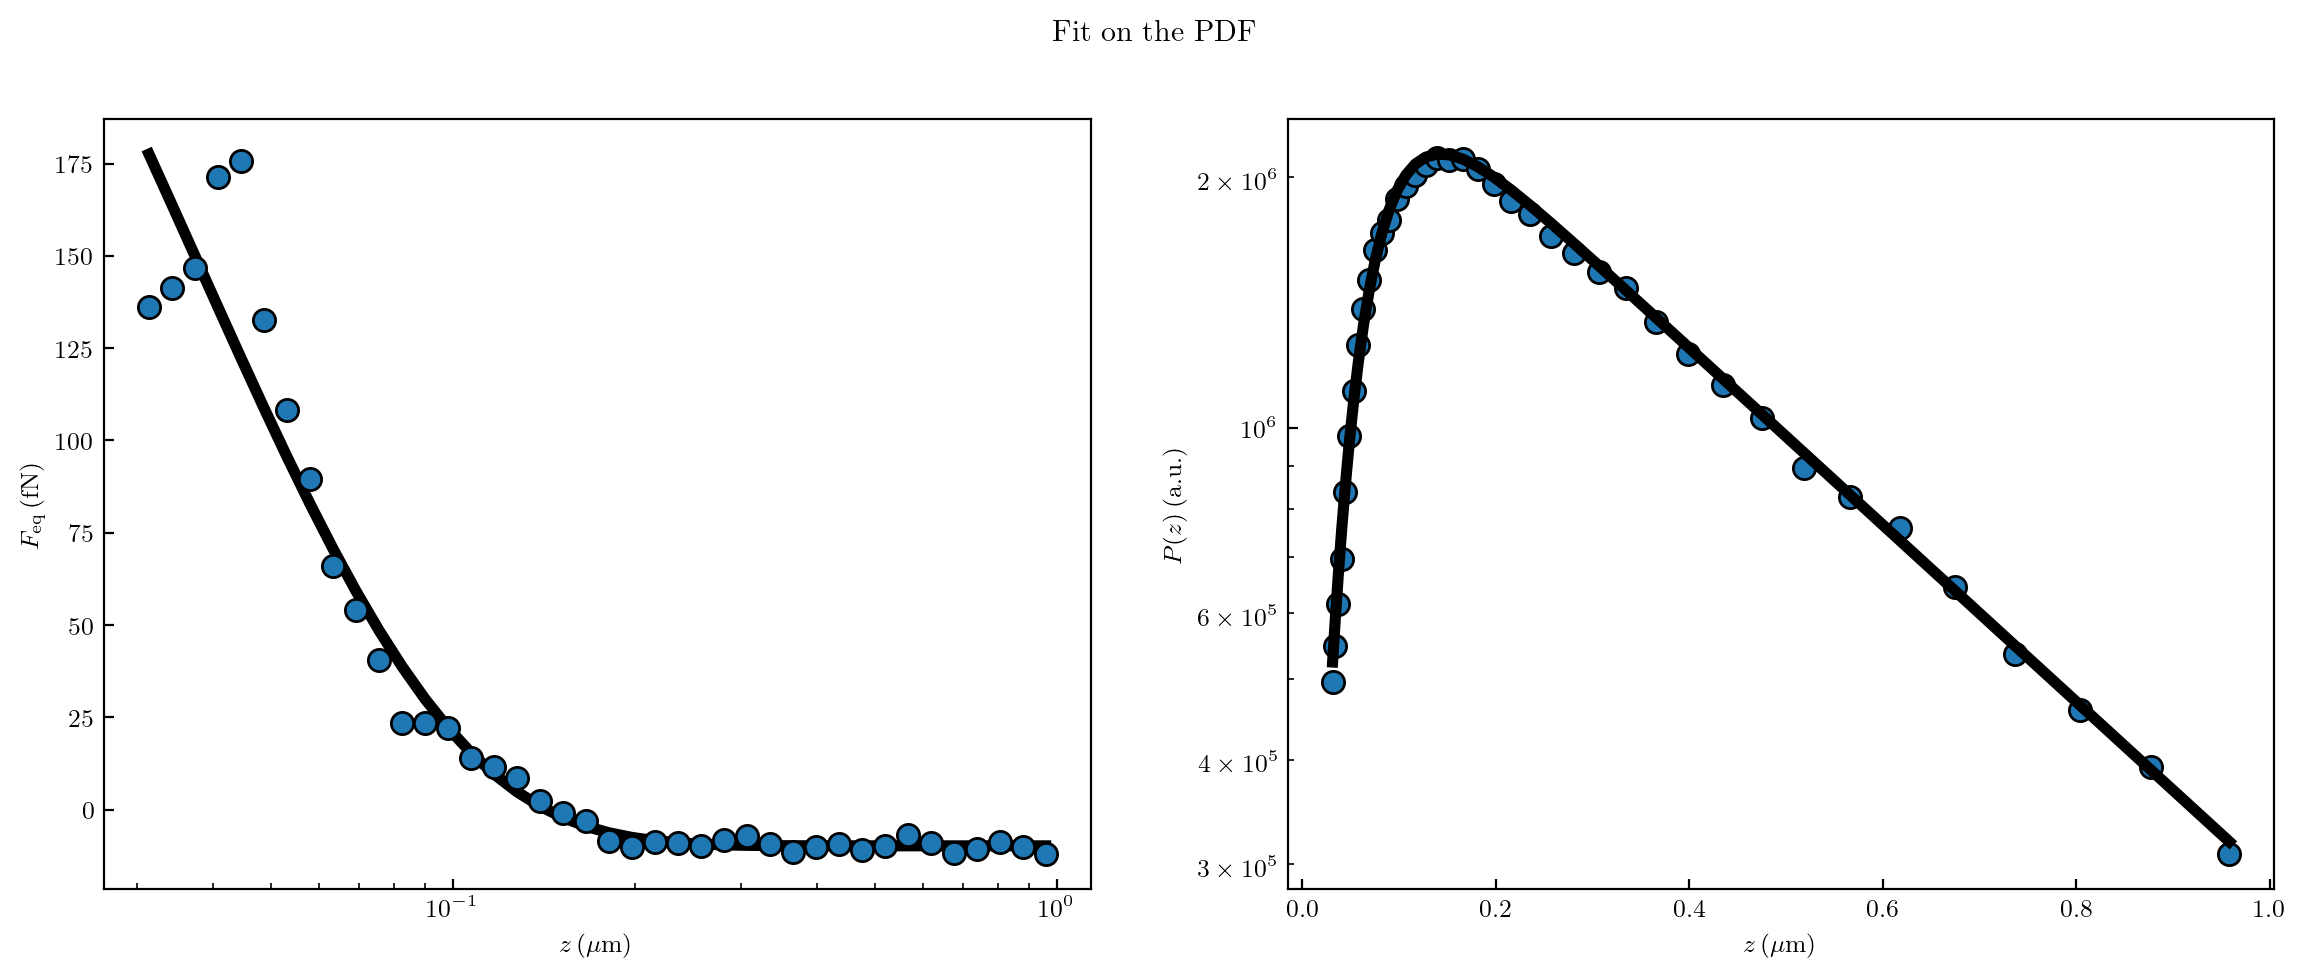

From the pdf: [B, lD, offset_pdf] = 
[ 5.90407702e+00  3.77557442e-08 -1.41484880e-08]


In [54]:
fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(14,5))

ax1.errorbar(
    x_F_eq * 1e6, y_F_eq * 1e15, yerr=0, 
    ls='', marker='o', markersize=8, markerfacecolor='tab:blue', markeredgewidth=1, markeredgecolor='k', 
    ecolor='k', capsize=3,
)
ax1.plot(x_F_eq * 1e6, F_eq_semi_theory(x_F_eq, *popt_P_eq[:]) * 1e15, ls='-', c='k', linewidth=4)
ax1.set_xlabel(r"$z \, \mathrm{(\mu m)}$")
ax1.set_ylabel(r"$F_{\mathrm{eq}} \, \mathrm{(fN)}$")
ax1.set_xscale("log")

ax2.errorbar(
    x_P_eq * 1e6, y_P_eq, yerr=0, 
    ls='', marker='o', markersize=8, markerfacecolor='tab:blue', markeredgewidth=1, markeredgecolor='k', 
    ecolor='k', capsize=3,
    zorder=-1,
)
ax2.plot(x_P_eq * 1e6, P_eq_semi_theory(x_P_eq, *popt_P_eq[:]), ls='-', c='k', linewidth=4)
ax2.set_xlabel("$z \, \mathrm{(\mu m)}$")
ax2.set_ylabel("$P(z) \, \mathrm{(a.u.)}$")
ax2.set_yscale("log")

fig.suptitle("Fit on the PDF")

plt.show()

print("From the pdf: [B, lD, offset_pdf] = ")
print(popt_P_eq)

In [55]:
# Check that the PDF is normed
print("Integral of the theoretical Peq = {0}".format(np.trapezoid(P_eq_semi_theory(x_F_eq, *popt_P_eq), x_F_eq)))

Integral of the theoretical Peq = 0.9999999999999997


In [56]:
# Save data

tosave["min_distance"] = min_distance
tosave["max_distance"] = max_distance
tosave["n_bins"] = n_bins

tosave["x_P_eq"] = np.copy(x_P_eq)
tosave["width_P_eq"] = np.copy(width_P_eq)
tosave["y_P_eq"] = np.copy(y_P_eq)

tosave["x_F_eq"] = np.copy(x_F_eq)
tosave["width_F_eq"] = np.copy(width_F_eq)
tosave["y_F_eq"] = np.copy(y_F_eq)

tosave["lB_theory"] = lB_theory

## Mean Diffusion Coefficient: MSD vs. PDF

In [57]:
def Dz_z(z, b=0, nl=0):
    z = z + b
    res = (6 * z * z + 2 * r * z) / (6 * z * z + 9 * r * z + 2 * r * r)
    res += nl
    return res

def Dx_z(z, b=0, nl=0):
    z = z + b 
    res = 1 - 9/16 * (r / (z + r)) + 1/8 * (r / (z + r)) ** 3 - 45/256 * (r / (z + r)) ** 4 - 1/16 * (r / (z + r)) ** 5
    res += nl
    return res

def minimizer(x):
    B = x[0]
    lD = x[1]
    # lB = x[2]
    b = x[2]
    
    xxx = np.linspace(10e-9, 5e-6, 1000)
    
    mean_D_para_from_pdf = np.trapezoid(Dx_z(xxx, b) * P_eq_semi_theory(xxx, *x[:2]), xxx)
    res = (mean_D_para_from_pdf - mean_D_para_from_MSD)**2 / mean_D_para_from_MSD**2
    
    mean_D_perp_from_pdf = np.trapezoid(Dz_z(xxx, b) * P_eq_semi_theory(xxx, *x[:2]), xxx)
    res += (mean_D_perp_from_pdf - mean_D_perp_from_MSD)**2 / mean_D_perp_from_MSD**2
    
    return res

In [59]:
# minimizer([0])

In [60]:
minimize_mean_D = minimize(
    minimizer, list(popt_P_eq[:2]) + [0], 
    method="BFGS", 
    tol=1e-10, 
)

/tmp/ipykernel_14693/3598414829.py:14: RuntimeWarning: overflow encountered in exp
  P_b = np.exp(-B * np.exp(-z / lD) - z / lB_exp)
/tmp/ipykernel_14693/3598414829.py:14: RuntimeWarning: overflow encountered in multiply
  P_b = np.exp(-B * np.exp(-z / lD) - z / lB_exp)


In [61]:
minimizer(minimize_mean_D.x)

np.float64(0.00033151265064637603)

In [62]:
b = minimize_mean_D.x[2]

xxx = np.linspace(10e-9, 5e-6, 1000)

mean_D_para_from_pdf = np.trapezoid(Dx_z(xxx, b) * P_eq_semi_theory(xxx, *minimize_mean_D.x[:2]), xxx)
mean_D_perp_from_pdf = np.trapezoid(Dz_z(xxx, b) * P_eq_semi_theory(xxx, *minimize_mean_D.x[:2]), xxx)

del xxx

print("Mean D para = {0:.3f}D0 (from MSD) and {1:.3f}D0 (from PDF)".format(mean_D_para_from_MSD, mean_D_para_from_pdf))
print("Mean D perp = {0:.3f}D0 (from MSD) and {1:.3f}D0 (from PDF)".format(mean_D_perp_from_MSD, mean_D_perp_from_pdf))
print(minimize_mean_D.x[0])
print(minimize_mean_D.x[1] * 1e9)
print("Estimated 'slip length' = {0:.1f} nm".format(b * 1e9))
print()

Mean D para = 0.512D0 (from MSD) and 0.517D0 (from PDF)
Mean D perp = 0.188D0 (from MSD) and 0.191D0 (from PDF)
5.904077024382838
95.38825326595041
Estimated 'slip length' = 31.3 nm



## Diffusion as a Function of the Distance to the Wall

In [63]:
# Domain to plot the diffusion profile
z_min_force = min_distance #10e-9
z_max_force = max_distance #2e-6
N_bins_force = n_bins 

In [64]:
timestep_diffusion = 1

### Determine the optimal polynomial order for Ronceray

In [65]:
all_orders = True

In [ ]:
if all_orders:

    pos = np.ones((len(x), 3))
    
    x_new = x - np.min(x)
    y_new = y - np.min(y)
    z_new = np.copy(z_dedrift)

    pos[:, 0] = x_new
    pos[:, 1] = y_new
    pos[:, 2] = z_new
    
    dt = timestep_diffusion / fps
    
    Dx1, Dy1, Dz1, z_D1 = Compute_diffusion(pos, dt, z_min=z_min_force, z_max=z_max_force, N=N_bins_force, ordre=1, method="Vestergaard")
    Dx2, Dy2, Dz2, z_D2 = Compute_diffusion(pos, dt, z_min=z_min_force, z_max=z_max_force, N=N_bins_force, ordre=2, method="Vestergaard")
    Dx3, Dy3, Dz3, z_D3 = Compute_diffusion(pos, dt, z_min=z_min_force, z_max=z_max_force, N=N_bins_force, ordre=3, method="Vestergaard")
    Dx4, Dy4, Dz4, z_D4 = Compute_diffusion(pos, dt, z_min=z_min_force, z_max=z_max_force, N=N_bins_force, ordre=4, method="Vestergaard")
    # Dx5, Dy5, Dz5, z_D5, err_Dz5 = Compute_diffusion(pos, dt, z_min=z_min_force, z_max=z_max_force, N=N_bins_force, ordre=5, method="Vestergaard")
    
    del pos, x_new, y_new, z_new
    
    D_para_z1 = (Dx1 + Dy1) / 2 
    D_para_z2 = (Dx2 + Dy2) / 2 
    D_para_z3 = (Dx3 + Dy3) / 2 
    D_para_z4 = (Dx4 + Dy4) / 2 
    # D_para_z5 = (Dx5 + Dy5) / 2 

    D_perp_z1 = Dz1 
    D_perp_z2 = Dz2 
    D_perp_z3 = Dz3 
    D_perp_z4 = Dz4 
    # D_perp_z5 = Dz5 

In [ ]:
# r

In [ ]:
# D0 = 4e-21 / (6*np.pi*eta_m*r)

In [ ]:
def min_arrays(t1, t2):
    if t1[0] < t2[0]:
        return t1
    return t2

def max_arrays(t1, t2):
    if t1[0] < t2[0]:
        return t2
    return t1

In [ ]:
if all_orders:

    fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(12,5))

    colors = ['lightsteelblue', 'tab:green', 'tab:blue', 'tab:orange', 'tab:red']

    ax1.plot(z_D1 * 1e6, D_para_z1, 'o', color=colors[0], label='1')
    ax1.plot(z_D2 * 1e6, D_para_z2, 'o', color=colors[1], label='2')
    ax1.plot(z_D3 * 1e6, D_para_z3, 'o', color=colors[2], label='3')
    ax1.plot(z_D4 * 1e6, D_para_z4, 'o', color=colors[3], label='4')
    ax1.plot(z_D1 * 1e6, D0 * Dx_z(z_D1, 0, nl=0), ls='--', c='k', linewidth=2)
    ax1.plot(z_D1 * 1e6, D0 * np.ones(len(z_D1)), ls='--', c='gray', linewidth=2)

    ax1.legend(frameon=False, title='Ordre')
    
    ax1.set(
        xlabel="$z$ (µm)", 
        ylabel=r"$D_\parallel$ ($\mathrm{m^2/s}$)", 
        xscale='log', 
        yscale='log', 
    )

    ax2.plot(z_D1 * 1e6, D_perp_z1, 'o', color=colors[0], label='1')
    ax2.plot(z_D2 * 1e6, D_perp_z2 - 0.02 * D0 * 0, 'o', color=colors[1], label='2')
    ax2.plot(z_D3 * 1e6, D_perp_z3, 'o', color=colors[2], label='3')
    ax2.plot(z_D4 * 1e6, D_perp_z4, 'o', color=colors[3], label='4')
    ax2.plot(z_D1 * 1e6, D0 * Dz_z(z_D1, 0, nl=0), ls='--', c='k', linewidth=2)
    ax2.plot(z_D1 * 1e6, D0 * np.ones(len(z_D1)), ls='--', c='gray', linewidth=2)

    ax2.legend(frameon=False, title='Ordre')
    [7.5, 24e-9, 0.] 
    ax2.set(
        xlabel=r"$z$ (µm)", 
        ylabel=r"$D_\perp$ ($\mathrm{m^2/s}$)", 
        xscale='log', 
        yscale='log', 
    )

    plt.show()